# HW1 — Feature Store Data Model: Movie Recommendation

## Scenario
We model a movie recommendation system. The ML task is to predict whether a user will give a movie a positive rating.

The schema separates:
- normalized business entities;
- offline historical features;
- online denormalized features;
- training events with a prediction timestamp and target variable.

The natural many-to-many relationship between users and movies is implemented through `hw2_ratings`.


## 1. ER Diagram — DBML

Paste this DBML into **dbdiagram.io** and export the resulting diagram as PNG or SVG.

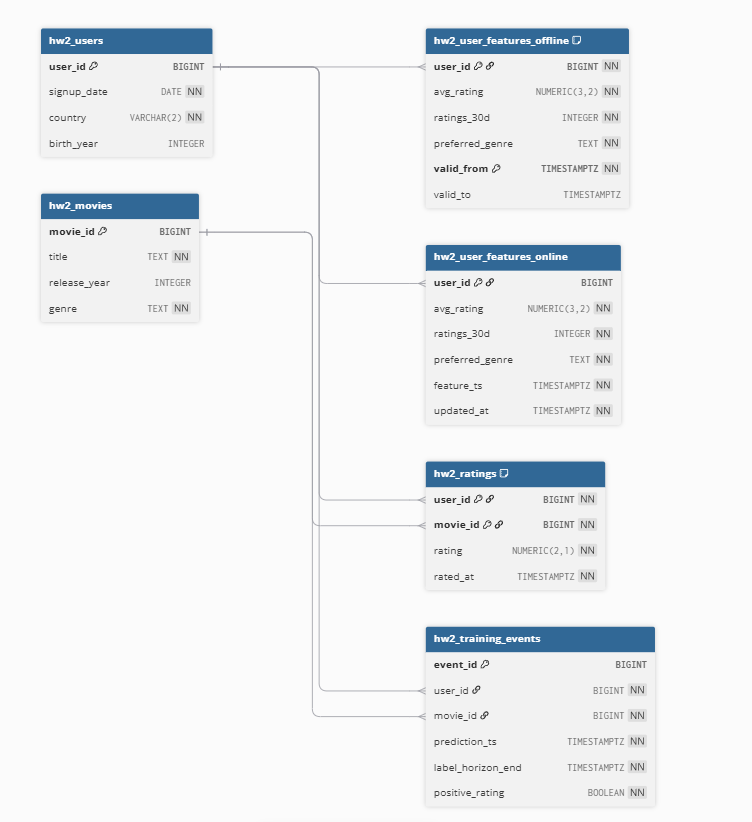

```dbml
Table hw2_users {
  user_id BIGINT [pk]
  signup_date DATE [not null]
  country VARCHAR(2) [not null]
  birth_year INTEGER
}

Table hw2_movies {
  movie_id BIGINT [pk]
  title TEXT [not null]
  release_year INTEGER
  genre TEXT [not null]
}

Table hw2_ratings {
  user_id BIGINT [not null, ref: > hw2_users.user_id]
  movie_id BIGINT [not null, ref: > hw2_movies.movie_id]
  rating NUMERIC(2,1) [not null]
  rated_at TIMESTAMPTZ [not null]

  indexes {
    (user_id, movie_id) [pk]
    (user_id, rated_at)
  }
}

Table hw2_user_features_offline {
  user_id BIGINT [not null, ref: > hw2_users.user_id]
  avg_rating NUMERIC(3,2) [not null]
  ratings_30d INTEGER [not null]
  preferred_genre TEXT [not null]
  valid_from TIMESTAMPTZ [not null]
  valid_to TIMESTAMPTZ

  indexes {
    (user_id, valid_from) [pk]
  }
}

Table hw2_training_events {
  event_id BIGINT [pk]
  user_id BIGINT [not null, ref: > hw2_users.user_id]
  movie_id BIGINT [not null, ref: > hw2_movies.movie_id]
  prediction_ts TIMESTAMPTZ [not null]
  label_horizon_end TIMESTAMPTZ [not null]
  positive_rating BOOLEAN [not null]
}

Table hw2_user_features_online {
  user_id BIGINT [pk, ref: > hw2_users.user_id]
  avg_rating NUMERIC(3,2) [not null]
  ratings_30d INTEGER [not null]
  preferred_genre TEXT [not null]
  feature_ts TIMESTAMPTZ [not null]
  updated_at TIMESTAMPTZ [not null]
}
```


In [1]:
# ============================================================
# PostgreSQL 16 setup for Google Colab
# Run this cell once before all SQL cells
# ============================================================

import subprocess
import sys
import time

print("1/5 Installing PostgreSQL 16...")
subprocess.run(
    ["bash", "-c", "apt-get update -qq && apt-get install -y postgresql-16 postgresql-client-16 -qq"],
    check=True
)

print("2/5 Starting PostgreSQL...")
subprocess.run(
    ["bash", "-c", "service postgresql start"],
    check=True
)

print("3/5 Creating database user...")

# Create user if it doesn't exist
result = subprocess.run(
    [
        "sudo", "-u", "postgres", "psql",
        "-tAc",
        "SELECT 1 FROM pg_roles WHERE rolname='hw2_user';"
    ],
    capture_output=True,
    text=True
)

if result.stdout.strip() != "1":
    subprocess.run(
        [
            "sudo", "-u", "postgres", "psql",
            "-c",
            "CREATE USER hw2_user WITH PASSWORD 'hw2_password';"
        ],
        check=True
    )
else:
    print("User hw2_user already exists.")

print("4/5 Creating database...")

# Create database if it doesn't exist
result = subprocess.run(
    [
        "sudo", "-u", "postgres", "psql",
        "-tAc",
        "SELECT 1 FROM pg_database WHERE datname='hw2_db';"
    ],
    capture_output=True,
    text=True
)

if result.stdout.strip() != "1":
    subprocess.run(
        [
            "sudo", "-u", "postgres", "createdb",
            "-O", "hw2_user",
            "hw2_db"
        ],
        check=True
    )
else:
    print("Database hw2_db already exists.")

print("5/5 Installing Python PostgreSQL driver...")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "psycopg2-binary"],
    check=True
)

# ============================================================
# Connect to PostgreSQL
# ============================================================

import psycopg2

# Close a previous connection if this cell is re-run
try:
    cur.close()
    conn.close()
except Exception:
    pass

conn = psycopg2.connect(
    host="localhost",
    port=5432,
    database="hw2_db",
    user="hw2_user",
    password="hw2_password"
)

conn.autocommit = True

cur = conn.cursor()

# Check PostgreSQL version
cur.execute("SELECT version();")
version = cur.fetchone()[0]

print()
print("==========================================")
print("PostgreSQL connection successful!")
print("==========================================")
print(version)
print()
print("Database: hw2_db")
print("User:     hw2_user")
print("Host:     localhost")
print("Port:     5432")

1/5 Installing PostgreSQL 16...
2/5 Starting PostgreSQL...
3/5 Creating database user...
4/5 Creating database...
5/5 Installing Python PostgreSQL driver...

PostgreSQL connection successful!
PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04.1) on x86_64-pc-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit

Database: hw2_db
User:     hw2_user
Host:     localhost
Port:     5432


### PostgreSQL execution
The next SQL sections are executed through the PostgreSQL connection created above.
`run_sql()` displays `SELECT` results as pandas tables in Colab.


In [2]:
cur.execute(r'''
SET TIME ZONE 'UTC';

DROP TABLE IF EXISTS
    hw2_training_events,
    hw2_user_features_online,
    hw2_user_features_offline,
    hw2_ratings,
    hw2_movies,
    hw2_users
CASCADE;

CREATE TABLE hw2_users (
    user_id BIGINT PRIMARY KEY,
    signup_date DATE NOT NULL,
    country VARCHAR(2) NOT NULL,
    birth_year INTEGER,
    CHECK (birth_year IS NULL OR birth_year BETWEEN 1900 AND 2020)
);

CREATE TABLE hw2_movies (
    movie_id BIGINT PRIMARY KEY,
    title TEXT NOT NULL,
    release_year INTEGER,
    genre TEXT NOT NULL,
    CHECK (release_year IS NULL OR release_year BETWEEN 1888 AND 2100)
);

CREATE TABLE hw2_ratings (
    user_id BIGINT NOT NULL
        REFERENCES hw2_users(user_id),
    movie_id BIGINT NOT NULL
        REFERENCES hw2_movies(movie_id),
    rating NUMERIC(2,1) NOT NULL
        CHECK (rating >= 0.0 AND rating <= 5.0),
    rated_at TIMESTAMPTZ NOT NULL,
    PRIMARY KEY (user_id, movie_id)
);

CREATE INDEX hw2_idx_ratings_user_time
    ON hw2_ratings (user_id, rated_at DESC);

CREATE TABLE hw2_user_features_offline (
    user_id BIGINT NOT NULL
        REFERENCES hw2_users(user_id),
    avg_rating NUMERIC(3,2) NOT NULL
        CHECK (avg_rating >= 0 AND avg_rating <= 5),
    ratings_30d INTEGER NOT NULL
        CHECK (ratings_30d >= 0),
    preferred_genre TEXT NOT NULL,
    valid_from TIMESTAMPTZ NOT NULL,
    valid_to TIMESTAMPTZ,

    PRIMARY KEY (user_id, valid_from),

    CHECK (
        valid_to IS NULL
        OR valid_to > valid_from
    )
);

CREATE INDEX hw2_idx_user_features_asof
    ON hw2_user_features_offline (user_id, valid_from DESC);

CREATE TABLE hw2_training_events (
    event_id BIGINT GENERATED BY DEFAULT AS IDENTITY PRIMARY KEY,
    user_id BIGINT NOT NULL
        REFERENCES hw2_users(user_id),
    movie_id BIGINT NOT NULL
        REFERENCES hw2_movies(movie_id),
    prediction_ts TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    positive_rating BOOLEAN NOT NULL,

    CHECK (label_horizon_end > prediction_ts)
);

CREATE INDEX hw2_idx_training_events_user_prediction
    ON hw2_training_events (user_id, prediction_ts);

CREATE TABLE hw2_user_features_online (
    user_id BIGINT PRIMARY KEY
        REFERENCES hw2_users(user_id),
    avg_rating NUMERIC(3,2) NOT NULL
        CHECK (avg_rating >= 0 AND avg_rating <= 5),
    ratings_30d INTEGER NOT NULL
        CHECK (ratings_30d >= 0),
    preferred_genre TEXT NOT NULL,
    feature_ts TIMESTAMPTZ NOT NULL,
    updated_at TIMESTAMPTZ NOT NULL DEFAULT CURRENT_TIMESTAMP
);

''')

print('SQL executed successfully.')

SQL executed successfully.


## 2. Test data

The offline feature table contains 10 historical rows for 3 users; user 1 has 3+ sequential versions.

In [3]:
cur.execute(r'''
INSERT INTO hw2_users (user_id, signup_date, country, birth_year) VALUES
(1, DATE '1990-01-10', 'UA', 1990),
(2, DATE '1988-04-15', 'PL', 1988),
(3, DATE '1995-07-20', 'ES', 1995);

INSERT INTO hw2_movies (movie_id, title, release_year, genre) VALUES
(101, 'The Matrix', 1999, 'Sci-Fi'),
(102, 'Inception', 2010, 'Sci-Fi'),
(103, 'Interstellar', 2014, 'Sci-Fi'),
(104, 'The Godfather', 1972, 'Crime'),
(105, 'The Dark Knight', 2008, 'Action'),
(106, 'Forrest Gump', 1994, 'Drama');

INSERT INTO hw2_ratings (user_id, movie_id, rating, rated_at) VALUES
(1, 101, 5.0, TIMESTAMPTZ '2024-10-05 10:00:00+00'),
(1, 102, 4.5, TIMESTAMPTZ '2024-10-20 10:00:00+00'),
(2, 104, 5.0, TIMESTAMPTZ '2024-10-12 10:00:00+00'),
(2, 105, 4.0, TIMESTAMPTZ '2024-11-01 10:00:00+00'),
(3, 106, 4.5, TIMESTAMPTZ '2024-10-15 10:00:00+00');

INSERT INTO hw2_user_features_offline
(user_id, avg_rating, ratings_30d, preferred_genre, valid_from, valid_to)
VALUES
(1, 4.20, 3, 'Sci-Fi',
 TIMESTAMPTZ '2024-10-01 00:00:00+00',
 TIMESTAMPTZ '2024-11-01 00:00:00+00'),
(1, 4.35, 5, 'Sci-Fi',
 TIMESTAMPTZ '2024-11-01 00:00:00+00',
 TIMESTAMPTZ '2024-12-01 00:00:00+00'),
(1, 4.50, 7, 'Sci-Fi',
 TIMESTAMPTZ '2024-12-01 00:00:00+00',
 NULL),

(2, 3.80, 2, 'Crime',
 TIMESTAMPTZ '2024-10-01 00:00:00+00',
 TIMESTAMPTZ '2024-11-10 00:00:00+00'),
(2, 4.00, 4, 'Crime',
 TIMESTAMPTZ '2024-11-10 00:00:00+00',
 TIMESTAMPTZ '2024-12-10 00:00:00+00'),
(2, 4.15, 6, 'Action',
 TIMESTAMPTZ '2024-12-10 00:00:00+00',
 NULL),

(3, 4.00, 1, 'Drama',
 TIMESTAMPTZ '2024-10-01 00:00:00+00',
 TIMESTAMPTZ '2024-11-05 00:00:00+00'),
(3, 4.10, 3, 'Drama',
 TIMESTAMPTZ '2024-11-05 00:00:00+00',
 TIMESTAMPTZ '2024-12-05 00:00:00+00'),
(3, 4.30, 5, 'Sci-Fi',
 TIMESTAMPTZ '2024-12-05 00:00:00+00',
 TIMESTAMPTZ '2025-01-01 00:00:00+00'),
(3, 4.40, 8, 'Sci-Fi',
 TIMESTAMPTZ '2025-01-01 00:00:00+00',
 NULL);

INSERT INTO hw2_training_events
(user_id, movie_id, prediction_ts, label_horizon_end, positive_rating)
VALUES
(1, 103, TIMESTAMPTZ '2024-10-20 12:00:00+00',
       TIMESTAMPTZ '2024-11-20 12:00:00+00', TRUE),
(1, 105, TIMESTAMPTZ '2024-11-20 12:00:00+00',
       TIMESTAMPTZ '2024-12-20 12:00:00+00', FALSE),
(2, 101, TIMESTAMPTZ '2024-11-15 12:00:00+00',
       TIMESTAMPTZ '2024-12-15 12:00:00+00', TRUE),
(2, 106, TIMESTAMPTZ '2024-12-20 12:00:00+00',
       TIMESTAMPTZ '2025-01-20 12:00:00+00', FALSE),
(3, 102, TIMESTAMPTZ '2024-10-20 12:00:00+00',
       TIMESTAMPTZ '2024-11-20 12:00:00+00', TRUE),
(3, 104, TIMESTAMPTZ '2024-11-20 12:00:00+00',
       TIMESTAMPTZ '2024-12-20 12:00:00+00', FALSE);

INSERT INTO hw2_user_features_online
(user_id, avg_rating, ratings_30d, preferred_genre, feature_ts)
VALUES
(1, 4.50, 7, 'Sci-Fi', TIMESTAMPTZ '2025-01-01 00:00:00+00'),
(2, 4.15, 6, 'Action', TIMESTAMPTZ '2025-01-01 00:00:00+00'),
(3, 4.40, 8, 'Sci-Fi', TIMESTAMPTZ '2025-01-01 00:00:00+00');

''')

print('SQL executed successfully.')

SQL executed successfully.


In [4]:
# Helper for executing SELECT queries and displaying results

import pandas as pd
from IPython.display import display

def run_sql(query):
    cur.execute(query)

    if cur.description:
        columns = [desc[0] for desc in cur.description]
        rows = cur.fetchall()
        display(pd.DataFrame(rows, columns=columns))
    else:
        print("Query executed successfully.")


## 3. Point-in-Time correctness

Every offline feature version is valid on the half-open interval `[valid_from, valid_to)`.

Therefore:
- `valid_from <= prediction_ts` means the version already existed;
- `valid_to > prediction_ts OR valid_to IS NULL` means it had not expired;
- `valid_to = NULL` means the version is currently valid.


### AS-OF SELECT #1

In [5]:
run_sql(r'''
SELECT user_id, avg_rating, ratings_30d, preferred_genre
FROM hw2_user_features_offline
WHERE user_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-10-20 12:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-10-20 12:00:00+00'
       OR valid_to IS NULL);
''')

,user_id,avg_rating,ratings_30d,preferred_genre
0,1,4.20,3,Sci-Fi


### AS-OF SELECT #2

In [6]:
run_sql(r'''
SELECT user_id, avg_rating, ratings_30d, preferred_genre,
       valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 3
  AND valid_from <= TIMESTAMPTZ '2024-12-20 12:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2024-12-20 12:00:00+00'
       OR valid_to IS NULL);
''')

,user_id,avg_rating,ratings_30d,preferred_genre,valid_from,valid_to
0,3,4.30,5,Sci-Fi,2024-12-05 00:00:00+00:00,2025-01-01 00:00:00+00:00


### AS-OF SELECT #3

In [7]:
run_sql(r'''
SELECT user_id, avg_rating, ratings_30d, preferred_genre,
       valid_from, valid_to
FROM hw2_user_features_offline
WHERE user_id = 2
  AND valid_from <= TIMESTAMPTZ '2025-01-01 00:00:00+00'
  AND (valid_to > TIMESTAMPTZ '2025-01-01 00:00:00+00'
       OR valid_to IS NULL);
''')

,user_id,avg_rating,ratings_30d,preferred_genre,valid_from,valid_to
0,2,4.15,6,Action,2024-12-10 00:00:00+00:00,None


### Training-data AS-OF JOIN

In [8]:
run_sql(r'''
SELECT
    e.event_id,
    e.user_id,
    e.movie_id,
    e.prediction_ts,
    e.label_horizon_end,
    e.positive_rating,
    f.avg_rating,
    f.ratings_30d,
    f.preferred_genre
FROM hw2_training_events AS e
LEFT JOIN hw2_user_features_offline AS f
    ON f.user_id = e.user_id
   AND f.valid_from <= e.prediction_ts
   AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
ORDER BY e.event_id;
''')

,event_id,user_id,movie_id,prediction_ts,label_horizon_end,positive_rating,avg_rating,ratings_30d,preferred_genre
0,1,1,103,2024-10-20 12:00:00+00:00,2024-11-20 12:00:00+00:00,True,4.20,3,Sci-Fi
1,2,1,105,2024-11-20 12:00:00+00:00,2024-12-20 12:00:00+00:00,False,4.35,5,Sci-Fi
2,3,2,101,2024-11-15 12:00:00+00:00,2024-12-15 12:00:00+00:00,True,4.00,4,Crime
3,4,2,106,2024-12-20 12:00:00+00:00,2025-01-20 12:00:00+00:00,False,4.15,6,Action
4,5,3,102,2024-10-20 12:00:00+00:00,2024-11-20 12:00:00+00:00,True,4.00,1,Drama
5,6,3,104,2024-11-20 12:00:00+00:00,2024-12-20 12:00:00+00:00,False,4.10,3,Drama


### Overlap check — expected result: 0 rows

In [10]:
run_sql(r'''
SELECT
    a.user_id,
    a.valid_from AS a_from,
    a.valid_to AS a_to,
    b.valid_from AS b_from,
    b.valid_to AS b_to
FROM hw2_user_features_offline AS a
JOIN hw2_user_features_offline AS b
  ON a.user_id = b.user_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;
''')

,user_id,a_from,a_to,b_from,b_to


## Why a simple JOIN would be wrong

```sql
JOIN hw2_user_features_offline f
  ON f.user_id = e.user_id
```

would attach **all historical versions** to every training event. This creates duplicate training examples and can attach feature values that were generated after `prediction_ts`.

That is data leakage and can artificially improve model evaluation. The temporal predicates ensure that each event receives only the feature version available at prediction time.


## 4. Normalization

`hw2_users`, `hw2_movies`, and `hw2_ratings` are normalized business tables. User attributes depend on `user_id`; movie attributes depend on `movie_id`; rating attributes depend on the `(user_id, movie_id)` relationship. The many-to-many relationship is therefore represented by the bridge table `hw2_ratings`.

`hw2_user_features_offline` is separate because features are derived and time-dependent. Its key `(user_id, valid_from)` identifies a particular historical version.

`hw2_user_features_online` is intentionally denormalized. The main read pattern is a direct lookup by `user_id`, so all current features are stored together to reduce joins and latency. The trade-off is duplicated information and a risk that online and offline values become inconsistent.

The online table should be refreshed from the same feature computation pipeline that produces offline features. `feature_ts` and `updated_at` make freshness observable.


## 5. Reflection

The hardest part of the design was point-in-time correctness. A model training example represents a prediction made at a specific time, so the feature vector must contain only information that was available at that moment. Using the current feature value would introduce future information and data leakage.

The main compromise was to keep business data normalized while deliberately denormalizing the online feature layer. Users, movies, and ratings are stable business facts and benefit from normalization. Historical features need temporal versions because derived values change over time. The online table contains the current feature vector in one row per user because the inference read pattern is a low-latency lookup by `user_id`.

The disadvantage of this design is possible inconsistency between offline and online features. In production, the online layer should be materialized from the same feature pipeline as the offline layer and should have freshness monitoring.

If the system had to serve a very large number of users with extremely low latency, the online layer could be materialized in a key-value store or cache, partitioned horizontally, and updated incrementally.

During six months of schema evolution, feature names, types, and semantics may change. Old models may still depend on previous definitions. Therefore feature definitions and versions should be tracked so that historical training data can be reproduced.
